# Notebook 4 — What Has the Model Learned? (SHAP) + Final Paper Figures

### Why interpretation matters

A model that predicts well but cannot be explained is hard to trust and hard to publish in a materials journal. Reviewers will ask: **"Does the model follow known metallurgy, or did it learn something strange from the data?"**

### What is SHAP? (a simple picture)

Think of a prediction as a **team result**. The model starts from the **average strength of all alloys** (the "base value"), and every feature "pushes" the prediction up or down:

$$\text{prediction} = \text{base value} + \text{push}_{\text{VEC}} + \text{push}_{\delta} + \text{push}_{T_m} + \dots$$

**SHAP** (SHapley Additive exPlanations) computes these pushes in a mathematically fair way, borrowing an idea from game theory (how to split a prize fairly between team members). A SHAP value of +200 MPa for δ means: *"for this alloy, its atomic-size mismatch raised the predicted strength by 200 MPa."*

### Questions in this notebook

| # | Question |
|---|---|
| Q1 | Which features matter most for yield strength? Are the results **stable**? |
| Q2 | Do the learned trends **agree with metallurgy** (VEC, size mismatch, melting point)? |
| Q3 | Does adding **hardness data (M4)** change what the model learns compared with **M0**? |
| Q4 | How does the model explain **one specific alloy**? |

At the end we collect **all figures and tables from Notebooks 1–4** into one folder, with draft captions for the paper.

## Step 1 — Import the libraries

In [1]:
import os
import re
import shutil                 # copy files
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import shap                   # pip install shap
from pymatgen.core import Element
from scipy.stats import spearmanr
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

COLOR_BLUE   = "#2a78d6"
COLOR_ORANGE = "#eb6834"
COLOR_GREEN  = "#1baf7a"
COLOR_GRAY   = "#8a8a85"

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


## Step 2 — Data and features (same as Notebooks 2 and 3)

Compact version of the data preparation explained in Notebooks 1 and 2.

In [2]:
# ---------- helper functions ----------
def parse_formula(formula):
    amounts = {}
    for element, amount in re.findall(r"([A-Z][a-z]?)([0-9.]+)", formula):
        amounts[element] = amounts.get(element, 0) + float(amount)
    total = sum(amounts.values())
    return {element: amount / total for element, amount in amounts.items()}

def make_composition_id(comp):
    return "-".join(f"{el}{round(frac, 3)}" for el, frac in sorted(comp.items()))

def make_system_id(comp):
    return "-".join(sorted(comp.keys()))

def element_radius(symbol):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        radius = Element(symbol).metallic_radius
    return float(radius) if radius else float(Element(symbol).atomic_radius)

def valence_electrons(symbol):
    group = Element(symbol).group
    return group if group <= 12 else group - 10

def physics_descriptors(comp, table):
    elements = list(comp.keys())
    c   = np.array([comp[el] for el in elements])
    r   = table.loc[elements, "radius"].values
    chi = table.loc[elements, "electroneg"].values
    r_mean, chi_mean = np.sum(c * r), np.sum(c * chi)
    return {
        "delta_size_mismatch": 100 * np.sqrt(np.sum(c * (1 - r / r_mean) ** 2)),
        "S_mix":     -8.314 * np.sum(c * np.log(c)),
        "VEC":       np.sum(c * table.loc[elements, "vec"].values),
        "chi_mean":  chi_mean,
        "delta_chi": np.sqrt(np.sum(c * (chi - chi_mean) ** 2)),
        "Tm_mean":   np.sum(c * table.loc[elements, "melting_K"].values),
        "r_mean":    r_mean,
        "n_elements": len(elements),
    }

# ---------- load and clean ----------
DATA_FILE = "data/MPEA_dataset.csv"
if not os.path.exists(DATA_FILE):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/CitrineInformatics/MPEA_dataset/master/MPEA_dataset.csv", DATA_FILE)

raw = pd.read_csv(DATA_FILE).rename(columns={
    "IDENTIFIER: Reference ID": "ref_id", "FORMULA": "formula",
    "PROPERTY: Processing method": "processing", "PROPERTY: HV": "hardness_HV",
    "PROPERTY: Type of test": "test_type", "PROPERTY: Test temperature ($^\\circ$C)": "test_temp_C",
    "PROPERTY: YS (MPa)": "yield_strength_MPa"})
raw["processing"]     = raw["processing"].fillna("unknown")
raw["test_type"]      = raw["test_type"].fillna("unknown")
raw["composition"]    = raw["formula"].apply(parse_formula)
raw["composition_id"] = raw["composition"].apply(make_composition_id)
raw["system_id"]      = raw["composition"].apply(make_system_id)

strength = raw[raw["yield_strength_MPa"].notna() & raw["test_temp_C"].between(20, 30)]
strength = strength[(strength["yield_strength_MPa"] > 0) & (strength["yield_strength_MPa"] < 5000)].reset_index(drop=True)
hardness = raw[raw["hardness_HV"].notna()].drop_duplicates(
    subset=["composition_id", "processing", "hardness_HV", "ref_id"]).reset_index(drop=True)

# ---------- features ----------
both_tables = pd.concat([strength.assign(source="strength"),
                         hardness.assign(source="hardness", test_type="hardness")], ignore_index=True)
all_elements = sorted({el for comp in both_tables["composition"] for el in comp})
element_table = pd.DataFrame({
    "radius":     {el: element_radius(el) for el in all_elements},
    "electroneg": {el: float(Element(el).X) for el in all_elements},
    "melting_K":  {el: float(Element(el).melting_point) for el in all_elements},
    "vec":        {el: valence_electrons(el) for el in all_elements},
})
fractions  = pd.DataFrame(list(both_tables["composition"])).fillna(0).add_prefix("frac_")
physics    = pd.DataFrame([physics_descriptors(c, element_table) for c in both_tables["composition"]])
categories = pd.get_dummies(both_tables[["test_type", "processing"]], prefix=["test", "proc"], dtype=int)
features_all = pd.concat([fractions, physics, categories], axis=1)

is_strength_row   = (both_tables["source"] == "strength").values
X_strength        = features_all[is_strength_row].reset_index(drop=True)
X_hardness        = features_all[~is_strength_row].reset_index(drop=True)
y_strength        = strength["yield_strength_MPa"].values
y_hardness_pseudo = hardness["hardness_HV"].values * 9.807 / 3

# Names of the feature groups
FRACTION_COLS  = list(fractions.columns)
PHYSICS_COLS   = list(physics.columns)
CONDITION_COLS = list(categories.columns)        # test type + processing
print(f"Strength rows: {len(X_strength)}, hardness rows: {len(X_hardness)}")

Strength rows: 722, hardness rows: 516


## Step 3 — Which model should we interpret?

Our models use **element fractions** *and* **physics descriptors**. These overlap a lot: for example, the VEC is computed *from* the element fractions. When features carry the same information, SHAP splits the credit between them in a way that is hard to read ("is it VEC or the Ni content?").

**Solution:** interpret a model that uses only the **8 physics descriptors + test/processing conditions**. This is fine *only if* that model is about as accurate as the full model. Let's check with the same grouped cross-validation as Notebook 2 (one seed, to save time).

In [3]:
PSEUDO_WEIGHT = 0.5

def make_model(seed=0):
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                        subsample=0.8, colsample_bytree=0.8, random_state=seed, n_jobs=-1)

def make_training_set(train_rows, method):
    '''M0 = strength only; M4 = strength + all hardness pseudo-strengths (weight 0.5).'''
    X = X_strength[train_rows]
    y = y_strength[train_rows]
    w = np.ones(train_rows.sum())
    if method == "M4":
        X = pd.concat([X, X_hardness])
        y = np.concatenate([y, y_hardness_pseudo])
        w = np.concatenate([w, np.full(len(y_hardness_pseudo), PSEUDO_WEIGHT)])
    return X, y, w

def assign_group_folds(groups, n_folds, seed):
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(seed)
    rng.shuffle(unique_groups)
    return {group: i % n_folds for i, group in enumerate(unique_groups)}

def grouped_cv_r2(columns, method, group_column, seed=0):
    '''R² from grouped 5-fold cross-validation using only the given feature columns.'''
    groups = strength[group_column].values
    fold = pd.Series(groups).map(assign_group_folds(groups, 5, seed)).values
    pred = np.zeros(len(y_strength))
    for f in range(5):
        train, test = fold != f, fold == f
        X, y, w = make_training_set(train, method)
        model = make_model(seed).fit(X[columns], y, sample_weight=w)
        pred[test] = model.predict(X_strength.loc[test, columns])
    return r2_score(y_strength, pred)

feature_sets = {
    "All features":                  FRACTION_COLS + PHYSICS_COLS + CONDITION_COLS,
    "Physics descriptors + conditions": PHYSICS_COLS + CONDITION_COLS,
}
rows = []
for set_name, columns in feature_sets.items():
    for method in ["M0", "M4"]:
        rows.append({"Features": set_name, "Method": method,
                     "R² new alloy":        grouped_cv_r2(columns, method, "composition_id"),
                     "R² new alloy family": grouped_cv_r2(columns, method, "system_id")})
pd.DataFrame(rows).round(3)

,Features,Method,R² new alloy,R² new alloy family
0,All features,M0,0.676,0.521
1,All features,M4,0.711,0.624
2,Physics descriptors + conditions,M0,0.623,0.526
3,Physics descriptors + conditions,M4,0.697,0.612


If the two feature sets give similar R² (within a few hundredths), the simpler physics model is a fair stand-in for interpretation. Note this in the paper: *"For interpretability, SHAP analysis was performed on a model restricted to physics descriptors and experimental conditions, whose grouped-CV accuracy was comparable to the full model."*

## Step 4 — Train the two models we will explain

We now train **M0** (strength data only) and **M4** (strength + hardness pseudo-strengths) on **all** data. These models are for **explanation only**; all accuracy numbers come from cross-validation (Step 3 and Notebooks 1–3).

In [4]:
INTERP_COLS = PHYSICS_COLS + CONDITION_COLS
all_rows = np.ones(len(y_strength), dtype=bool)

models = {}
for method in ["M0", "M4"]:
    X, y, w = make_training_set(all_rows, method)
    models[method] = make_model(0).fit(X[INTERP_COLS], y, sample_weight=w)

# The alloys we explain: the real strength measurements
X_explain = X_strength[INTERP_COLS]
print("Models trained. Explaining", len(X_explain), "real strength measurements.")

Models trained. Explaining 722 real strength measurements.


## Step 5 — Compute SHAP values

`shap.TreeExplainer` is a fast, exact SHAP method for tree models like XGBoost. It returns a table with **one SHAP value per alloy per feature**.

We also check the key SHAP property: **base value + sum of all SHAP values = model prediction** (for every alloy). If this check passes, we can trust that the pushes add up correctly.

In [5]:
shap_values = {}
base_values = {}
for method, model in models.items():
    explainer = shap.TreeExplainer(model)
    shap_values[method] = explainer.shap_values(X_explain)        # shape: (alloys, features)
    base_values[method] = float(np.ravel(explainer.expected_value)[0])

    # Check: base + sum of pushes = prediction
    reconstructed = base_values[method] + shap_values[method].sum(axis=1)
    max_difference = np.max(np.abs(reconstructed - model.predict(X_explain)))
    print(f"{method}: base value = {base_values[method]:.0f} MPa, "
          f"largest difference between (base + SHAP sum) and prediction = {max_difference:.3f} MPa")

M0: base value = 1023 MPa, largest difference between (base + SHAP sum) and prediction = 0.003 MPa


M4: base value = 1167 MPa, largest difference between (base + SHAP sum) and prediction = 0.003 MPa


### Step 5b — Readable names and grouping the condition columns

The test type and processing are stored as several 0/1 columns (e.g. `test_C`, `test_T`, `proc_CAST`, ...). For a clean picture we **add up** their SHAP values into two groups, **"Test type"** and **"Processing"**. Because SHAP values are additive, adding them is allowed.

In [6]:
NICE_NAMES = {
    "delta_size_mismatch": "δ (atomic size mismatch)",
    "S_mix":               "ΔS_mix (mixing entropy)",
    "VEC":                 "VEC (valence electrons)",
    "chi_mean":            "Mean electronegativity χ",
    "delta_chi":           "Δχ (electroneg. difference)",
    "Tm_mean":             "Mean melting point Tm",
    "r_mean":              "Mean atomic radius r",
    "n_elements":          "Number of elements",
}

def grouped_shap_table(values):
    '''Turn the SHAP array into a table: physics descriptors + summed "Test type" and "Processing".'''
    table = pd.DataFrame(values, columns=INTERP_COLS)
    grouped = table[PHYSICS_COLS].rename(columns=NICE_NAMES)
    grouped["Test type"]  = table[[c for c in INTERP_COLS if c.startswith("test_")]].sum(axis=1)
    grouped["Processing"] = table[[c for c in INTERP_COLS if c.startswith("proc_")]].sum(axis=1)
    return grouped

grouped_shap = {method: grouped_shap_table(values) for method, values in shap_values.items()}
grouped_shap["M4"].head()

,δ (atomic size mismatch),ΔS_mix (mixing entropy),VEC (valence electrons),Mean electronegativity χ,Δχ (electroneg. difference),Mean melting point Tm,Mean atomic radius r,Number of elements,Test type,Processing
0,-122.565353,-128.984818,-215.038300,-5.515758,-63.414024,-54.420650,-250.058716,-19.231958,-39.539345,-103.897377
1,111.734337,-104.038956,-263.604645,-10.731647,-62.221611,-111.884178,-208.212204,-16.815395,-63.977512,-90.659950
2,157.189301,-78.638893,-117.430031,45.534046,-36.395050,-169.351013,7.210558,-25.436838,-49.145123,-65.260391
3,140.375443,-95.023010,56.540756,72.819496,-42.836632,-229.618057,121.646431,-29.579788,-88.856049,-72.160736
4,-223.959381,-116.347130,-195.396835,3.559640,-57.996010,2.712333,-256.322723,-16.528748,-21.826664,-100.154869


## Step 6 — Q1: Which features matter most, and is that stable?

**Global importance** = the average size of a feature's push, `mean(|SHAP|)`, in MPa.

A single model can be a bit lucky or unlucky, so we also refit each model on **5 bootstrap resamples** of the data and recompute the importance. The error bars show how much the importance changes. A feature whose bar is clearly longer than the others *including* its error bar is a robust result.

In [7]:
N_BOOT = 5
importance_runs = {"M0": [], "M4": []}

for method in ["M0", "M4"]:
    X, y, w = make_training_set(all_rows, method)
    X = X[INTERP_COLS].reset_index(drop=True)
    for b in range(N_BOOT):
        rng = np.random.default_rng(100 + b)
        rows = rng.integers(0, len(y), size=len(y))                   # bootstrap resample
        model_b = make_model(b).fit(X.iloc[rows], y[rows], sample_weight=w[rows])
        values_b = shap.TreeExplainer(model_b).shap_values(X_explain)
        importance_runs[method].append(grouped_shap_table(values_b).abs().mean())

importance_mean = {m: pd.concat(runs, axis=1).mean(axis=1) for m, runs in importance_runs.items()}
importance_std  = {m: pd.concat(runs, axis=1).std(axis=1)  for m, runs in importance_runs.items()}

importance_table = pd.DataFrame({
    "M0 mean |SHAP| (MPa)": importance_mean["M0"], "M0 std": importance_std["M0"],
    "M4 mean |SHAP| (MPa)": importance_mean["M4"], "M4 std": importance_std["M4"],
}).sort_values("M4 mean |SHAP| (MPa)", ascending=False)
importance_table.round(0)

,M0 mean |SHAP| (MPa),M0 std,M4 mean |SHAP| (MPa),M4 std
Mean atomic radius r,106.0,55.0,194.0,22.0
δ (atomic size mismatch),103.0,16.0,122.0,23.0
VEC (valence electrons),143.0,31.0,94.0,13.0
Test type,106.0,28.0,83.0,7.0
Processing,86.0,6.0,81.0,7.0
Mean melting point Tm,87.0,11.0,77.0,13.0
ΔS_mix (mixing entropy),71.0,6.0,63.0,3.0
Mean electronegativity χ,50.0,11.0,47.0,6.0
Δχ (electroneg. difference),32.0,6.0,35.0,5.0
Number of elements,7.0,2.0,10.0,6.0


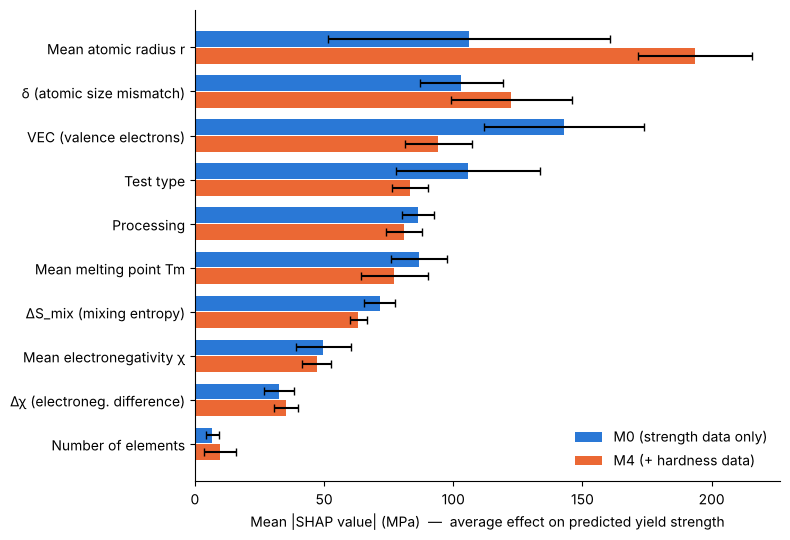

In [8]:
order = importance_table.index[::-1]           # most important at the top of the chart
y_pos = np.arange(len(order))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(y_pos + bar_height / 2, importance_mean["M0"][order], bar_height * 0.92,
        xerr=importance_std["M0"][order], capsize=3, color=COLOR_BLUE, label="M0 (strength data only)")
ax.barh(y_pos - bar_height / 2, importance_mean["M4"][order], bar_height * 0.92,
        xerr=importance_std["M4"][order], capsize=3, color=COLOR_ORANGE, label="M4 (+ hardness data)")
ax.set_yticks(y_pos)
ax.set_yticklabels(order)
ax.set_xlabel("Mean |SHAP value| (MPa)  —  average effect on predicted yield strength")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig9_shap_importance.png", dpi=300)
plt.show()

## Step 7 — The SHAP "beeswarm" plot

This plot shows **every alloy as one dot** for every physics descriptor:
* **horizontal position** = SHAP value (how much that feature pushed this alloy's strength up → or down ←),
* **colour** = the feature's value for that alloy (red = high, blue = low).

**How to read it:** for δ, if red dots sit on the right, *high size mismatch → higher strength*. For VEC, if red dots sit on the left, *high VEC → lower strength*.

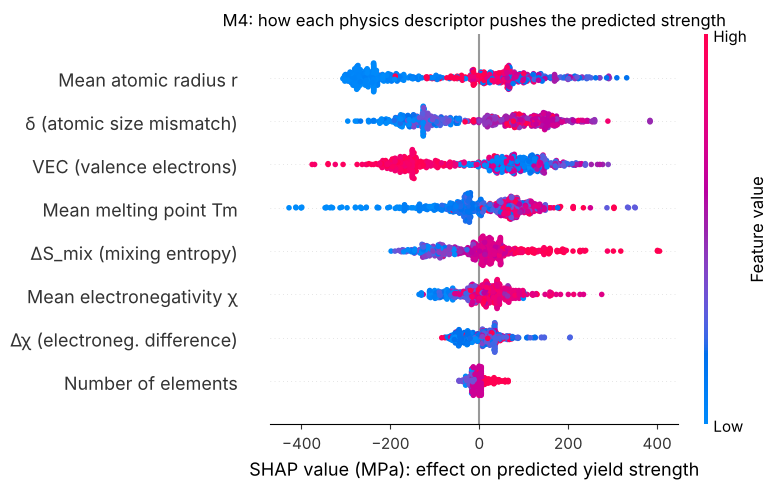

In [9]:
physics_shap_M4 = grouped_shap["M4"][[NICE_NAMES[c] for c in PHYSICS_COLS]]
physics_values  = X_explain[PHYSICS_COLS].rename(columns=NICE_NAMES)

shap.summary_plot(physics_shap_M4.values, physics_values, show=False, plot_size=(8, 5))
plt.xlabel("SHAP value (MPa): effect on predicted yield strength")
plt.title("M4: how each physics descriptor pushes the predicted strength")
plt.tight_layout()
plt.savefig("figures/fig10_shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 8 — Q2 & Q3: Do the trends agree with metallurgy? Does hardness data change them?

**Dependence plots** show, for one feature, its value (x-axis) against its SHAP value (y-axis). We draw **M0 and M4 together** to see whether adding hardness data changes the learned trend.

What metallurgy expects:

| Descriptor | Expected trend | Reason |
|---|---|---|
| VEC | ↓ strength as VEC increases (at least from BCC to FCC) | Low VEC (< 6.87) → BCC structure, strong; high VEC (≥ 8) → FCC, softer and more ductile |
| δ (size mismatch) | ↑ strength as δ increases | More lattice distortion → more solid-solution strengthening |
| Mean melting point Tm | ↑ strength as T̄m increases | Stronger atomic bonding (e.g. refractory HEAs with W, Mo, Ta, Nb) |
| ΔS_mix | unclear | Entropy mainly affects phase stability, not strength directly |

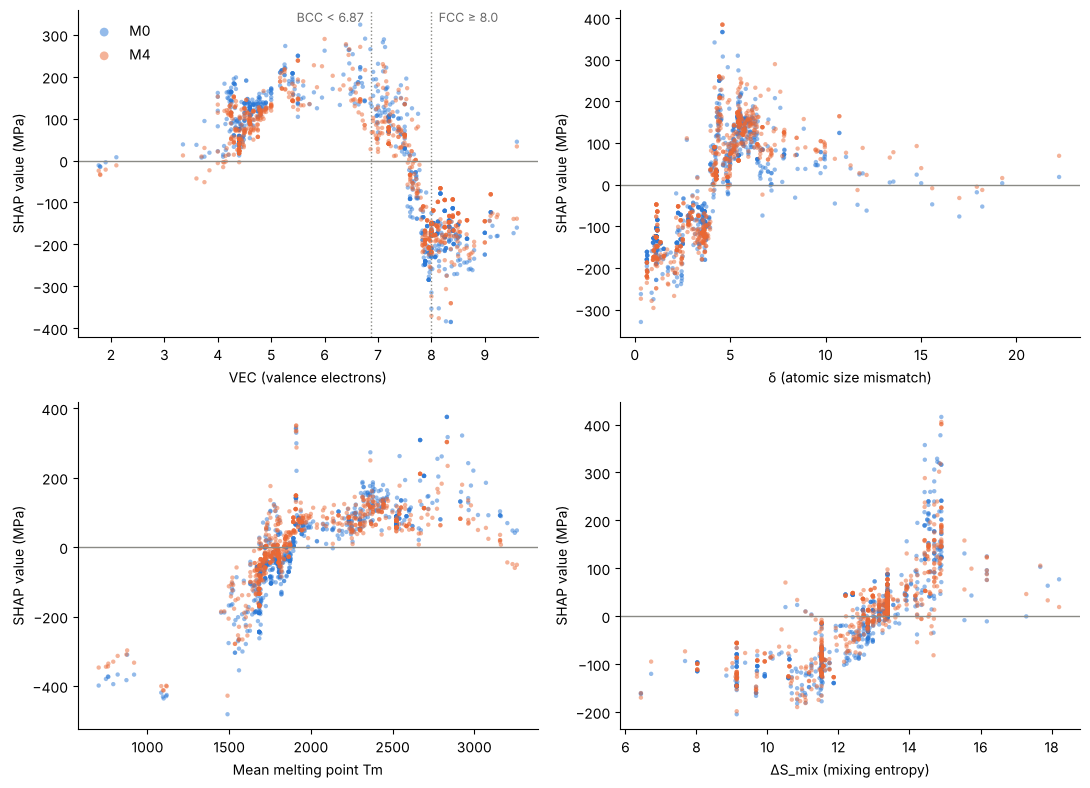

In [10]:
features_to_plot = ["VEC", "delta_size_mismatch", "Tm_mean", "S_mix"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), features_to_plot):
    column = INTERP_COLS.index(feature)
    for method, color in [("M0", COLOR_BLUE), ("M4", COLOR_ORANGE)]:
        ax.scatter(X_explain[feature], shap_values[method][:, column], s=10, alpha=0.5,
                   color=color, edgecolor="none", label=method)
    ax.axhline(0, color=COLOR_GRAY, linewidth=1)
    if feature == "VEC":
        # Classic phase-stability thresholds (Guo et al., 2011)
        top = ax.get_ylim()[1] * 0.92
        ax.axvline(6.87, color=COLOR_GRAY, linestyle=":", linewidth=1)
        ax.axvline(8.0,  color=COLOR_GRAY, linestyle=":", linewidth=1)
        ax.text(6.80, top, "BCC < 6.87 ", fontsize=9, color="dimgray", ha="right")   # label left of line
        ax.text(8.07, top, " FCC ≥ 8.0",  fontsize=9, color="dimgray", ha="left")    # label right of line
    ax.set_xlabel(NICE_NAMES[feature])
    ax.set_ylabel("SHAP value (MPa)")
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.savefig("figures/fig11_shap_dependence.png", dpi=300)
plt.show()

### Step 8b — A number for each trend

Pictures can fool us, so we also compute the **Spearman correlation** between each feature's value and its SHAP value. Positive = higher value → higher predicted strength. Then we compare the sign with metallurgical expectation.

In [11]:
expected_sign = {"VEC": -1, "delta_size_mismatch": +1, "Tm_mean": +1}

rows = []
for feature in PHYSICS_COLS:
    column = INTERP_COLS.index(feature)
    row = {"Descriptor": NICE_NAMES[feature]}
    for method in ["M0", "M4"]:
        row[f"Spearman {method}"] = spearmanr(X_explain[feature], shap_values[method][:, column]).correlation
    if feature in expected_sign:
        agrees = np.sign(row["Spearman M0"]) == expected_sign[feature] and np.sign(row["Spearman M4"]) == expected_sign[feature]
        row["Agrees with metallurgy?"] = "yes" if agrees else "NO"
    else:
        row["Agrees with metallurgy?"] = "(no clear expectation)"
    rows.append(row)

trend_table = pd.DataFrame(rows)
trend_table.round(2)

,Descriptor,Spearman M0,Spearman M4,Agrees with metallurgy?
0,δ (atomic size mismatch),0.78,0.82,yes
1,ΔS_mix (mixing entropy),0.89,0.86,(no clear expectation)
2,VEC (valence electrons),-0.71,-0.69,yes
3,Mean electronegativity χ,0.39,0.51,(no clear expectation)
4,Δχ (electroneg. difference),0.34,0.54,(no clear expectation)
5,Mean melting point Tm,0.87,0.81,yes
6,Mean atomic radius r,0.60,0.66,(no clear expectation)
7,Number of elements,0.80,0.84,(no clear expectation)


**A caution about "Test type"** (see the importance chart): in this dataset, brittle BCC alloys are mostly tested in **compression** and ductile FCC alloys in **tension**. So the SHAP value of the test type partly reflects *which kind of alloy* was tested, not only the physics of compression vs. tension. Mention this **confounding** in the paper rather than interpreting the test-type effect directly.

## Step 9 — Q4: Explaining one alloy

For a single alloy, we draw each feature's push as a bar: **orange bars push the predicted strength up, blue bars push it down.** The model starts from the base value (the average strength) and adds all the bars to reach its prediction.

We explain the famous refractory HEA **HfNbTaTiZr** (one of its measurements). Try other alloys by changing `ALLOY`.

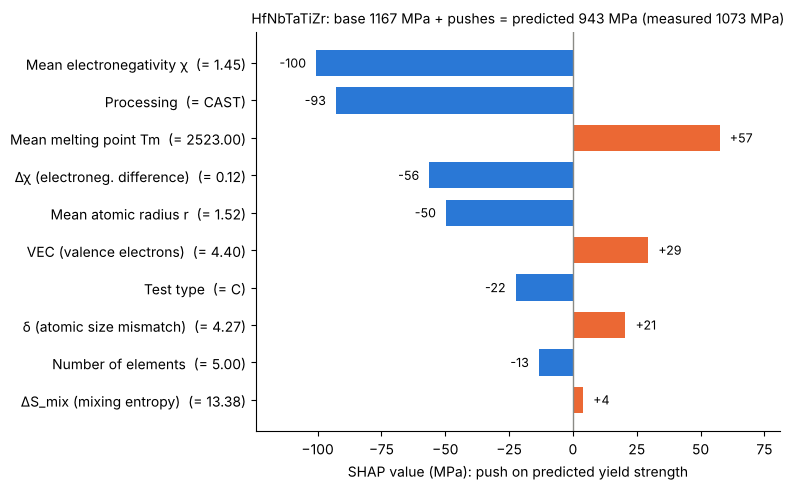

In [12]:
ALLOY = "Hf1 Nb1 Ta1 Ti1 Zr1"

row_number = strength.index[strength["formula"] == ALLOY][0]
pushes     = grouped_shap["M4"].iloc[row_number]                 # one SHAP value per feature (group)
prediction = base_values["M4"] + pushes.sum()

# Text shown next to each bar: the feature's value for this alloy
values_text = {NICE_NAMES[c]: f"{X_explain[c].iloc[row_number]:.2f}" for c in PHYSICS_COLS}
values_text["Test type"]  = strength.loc[row_number, "test_type"]
values_text["Processing"] = strength.loc[row_number, "processing"]

# Sort so the biggest push (up or down) is at the top
pushes = pushes.reindex(pushes.abs().sort_values().index)
labels = [f"{name}  (= {values_text[name]})" for name in pushes.index]
colors = [COLOR_ORANGE if v > 0 else COLOR_BLUE for v in pushes.values]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels, pushes.values, color=colors, height=0.7)
ax.axvline(0, color=COLOR_GRAY, linewidth=1)
for y, v in enumerate(pushes.values):                          # write the MPa value at the end of each bar
    ax.text(v + (4 if v > 0 else -4), y, f"{v:+.0f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9)
ax.set_xlabel("SHAP value (MPa): push on predicted yield strength")
ax.set_title(f"{ALLOY.replace('1', '').replace(' ', '')}: base {base_values['M4']:.0f} MPa "
             f"+ pushes = predicted {prediction:.0f} MPa (measured {y_strength[row_number]:.0f} MPa)",
             fontsize=10)
ax.margins(x=0.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig12_shap_waterfall_HfNbTaTiZr.png", dpi=300)
plt.show()

*Note:* this model was trained on all data, including this alloy, so its prediction is "in-sample" and looks better than a real prediction would. Waterfall plots are for **explanation**, not for judging accuracy.

In [13]:
# Save the interpretation tables
importance_table.round(2).to_csv("results/table7_shap_importance.csv")
trend_table.round(3).to_csv("results/table8_shap_trends.csv", index=False)
print("Saved results/table7_shap_importance.csv and results/table8_shap_trends.csv")

Saved results/table7_shap_importance.csv and results/table8_shap_trends.csv


## Step 10 — Collect all figures and tables for the paper

This cell copies every figure from Notebooks 1–4 into a folder `paper_figures/`, with the numbering we suggest for the paper, and writes **draft captions** into `paper_figures/captions.md`. Edit the captions in your own words before submitting.

*(If you have not run Notebooks 1–3 in this folder, their figures are skipped with a message.)*

In [14]:
PAPER_FIGURES = [
    # (file from the notebooks, name in the paper, main text or supplement, draft caption)
    ("fig2_parity_three_splits.png",       "Figure_1", "Main",
     "Predicted vs. measured room-temperature yield strength (random forest) under random, composition-grouped "
     "and system-grouped 5-fold cross-validation. The same model appears far less accurate when test alloys "
     "(or alloy families) are excluded from training."),
    ("fig5_hardness_methods.png",          "Figure_2", "Main",
     "Grouped cross-validation R² (mean ± std over 5 seeds) for the five ways of using hardness data, "
     "for unseen alloys (blue) and unseen alloy families (orange). Left: alloys with a measured hardness; "
     "right: all alloys."),
    ("fig6_parity_baseline_vs_augment.png","Figure_3", "Main",
     "Parity plots for unseen alloy families: baseline (M0) vs. training with hardness-derived "
     "pseudo-strengths when hardness of the new alloys is available (M4)."),
    ("fig8_calibration_curves.png",        "Figure_4", "Main",
     "Calibration curves of the bootstrap-ensemble uncertainty (M4) before and after group-aware recalibration."),
    ("fig7_confidence_curve.png",          "Figure_5", "Main",
     "Confidence curve for unseen alloy families: MAE of the remaining predictions as the least-confident "
     "predictions are removed, compared with random and ideal (error-ordered) removal."),
    ("fig11_shap_dependence.png",          "Figure_6", "Main",
     "SHAP dependence of predicted yield strength on VEC, atomic size mismatch δ, mean melting point and "
     "mixing entropy for models trained without (M0) and with (M4) hardness data."),
    ("fig1_duplicates.png",                "Figure_S1", "Supplement",
     "Number of measurements per distinct alloy composition in the cleaned room-temperature dataset."),
    ("fig4_hardness_vs_strength.png",      "Figure_S2", "Supplement",
     "Measured yield strength vs. Tabor estimate (HV × 9.807 / 3) for alloys with both measurements."),
    ("fig3_feature_importance.png",        "Figure_S3", "Supplement",
     "Random-forest feature importances of the baseline model."),
    ("fig9_shap_importance.png",           "Figure_S4", "Supplement",
     "Global SHAP importance (mean |SHAP|, ± std over 5 bootstrap refits) for M0 and M4."),
    ("fig10_shap_beeswarm.png",            "Figure_S5", "Supplement",
     "SHAP beeswarm plot of the physics descriptors for M4."),
    ("fig12_shap_waterfall_HfNbTaTiZr.png","Figure_S6", "Supplement",
     "SHAP explanation of the M4 prediction for HfNbTaTiZr: contribution of each descriptor to the predicted yield strength."),
]

os.makedirs("paper_figures", exist_ok=True)
caption_lines = ["# Draft figure captions\n"]
for source, paper_name, section, caption in PAPER_FIGURES:
    source_path = os.path.join("figures", source)
    if os.path.exists(source_path):
        shutil.copy(source_path, os.path.join("paper_figures", paper_name + ".png"))
        caption_lines.append(f"**{paper_name.replace('_', ' ')}** ({section}). {caption}\n")
        print(f"copied  {source:40s} -> paper_figures/{paper_name}.png")
    else:
        print(f"MISSING {source:40s} (run the notebook that makes it)")

with open("paper_figures/captions.md", "w", encoding="utf-8") as f:
    f.write("\n".join(caption_lines))
print("\nCaptions written to paper_figures/captions.md")

copied  fig2_parity_three_splits.png             -> paper_figures/Figure_1.png
copied  fig5_hardness_methods.png                -> paper_figures/Figure_2.png
copied  fig6_parity_baseline_vs_augment.png      -> paper_figures/Figure_3.png
copied  fig8_calibration_curves.png              -> paper_figures/Figure_4.png
copied  fig7_confidence_curve.png                -> paper_figures/Figure_5.png
copied  fig11_shap_dependence.png                -> paper_figures/Figure_6.png
copied  fig1_duplicates.png                      -> paper_figures/Figure_S1.png
copied  fig4_hardness_vs_strength.png            -> paper_figures/Figure_S2.png
copied  fig3_feature_importance.png              -> paper_figures/Figure_S3.png
copied  fig9_shap_importance.png                 -> paper_figures/Figure_S4.png
copied  fig10_shap_beeswarm.png                  -> paper_figures/Figure_S5.png
copied  fig12_shap_waterfall_HfNbTaTiZr.png      -> paper_figures/Figure_S6.png

Captions written to paper_figures/captions.md

### Step 10b — One summary table of the main numbers

This reads the result files from Notebooks 1–3 (if present) and prints the key numbers you will quote in the **abstract** and **conclusions**.

In [15]:
def read_if_exists(path):
    return pd.read_csv(path) if os.path.exists(path) else None

nb1 = read_if_exists("results/table1_baseline_results.csv")
nb2 = read_if_exists("results/table2_per_seed_results.csv")
nb3 = read_if_exists("results/table5_calibration.csv")

if nb1 is not None:
    print("Notebook 1 — effect of honest validation (XGBoost R²):")
    print(nb1[nb1.Model == "XGBoost"][["Split", "R2", "MAE (MPa)"]].round(3).to_string(index=False), "\n")

if nb2 is not None:
    print("Notebook 2 — hardness methods, new alloy families (mean over seeds):")
    fam = nb2[nb2.Grouping == "New alloy family (system)"]
    print(fam.groupby("Method")[["R2 (all)", "MAE (all)", "R2 (subset)"]].mean().round(3).to_string(), "\n")

if nb3 is not None:
    print("Notebook 3 — 95% interval coverage (%), raw vs calibrated:")
    print(nb3[["Grouping", "Method", "Coverage raw XGB (%)", "Coverage calibrated XGB (%)"]].round(1).to_string(index=False))

Notebook 1 — effect of honest validation (XGBoost R²):
                Split    R2  MAE (MPa)
               Random 0.730    212.089
Grouped (composition) 0.684    242.319
     Grouped (system) 0.536    290.990 

Notebook 2 — hardness methods, new alloy families (mean over seeds):
                      R2 (all)  MAE (all)  R2 (subset)
Method                                                
M0 Baseline              0.545    290.982        0.506
M1 Tabor rule              NaN        NaN        0.430
M2 Hardness as input     0.607    273.428        0.586
M3 Augment (A)           0.550    292.045        0.494
M4 Augment (B)           0.645    266.505        0.639 

Notebook 3 — 95% interval coverage (%), raw vs calibrated:
                 Grouping Method  Coverage raw XGB (%)  Coverage calibrated XGB (%)
  New alloy (composition)     M0                  49.6                         94.2
  New alloy (composition)     M4                  47.1                         89.3
New alloy family (sy

## Summary — what we learned

Check these against your own tables (Steps 3, 6 and 8b). The pattern we observed:

1. **A physics-only model is nearly as accurate** as the full model, so its explanations are representative.
2. **The model follows known metallurgy**, with some interesting details visible in the dependence plots (Step 8):
   * **VEC:** alloys with VEC ≥ 8 (FCC) are predicted much weaker than BCC alloys, as expected. But the effect is **not simply "lower is stronger"**: it peaks around VEC ≈ 5–7 (BCC alloys rich in Mo, W, Cr, Nb) and is smaller for very low VEC (Ti/Zr/Hf-rich alloys, VEC ≈ 4). This matches the experimental observation that group-VI-rich refractory HEAs are among the strongest.
   * **Size mismatch δ:** strength rises steeply up to δ ≈ 5–6%, then levels off. Very large δ usually means intermetallic or multi-phase alloys, where the simple solid-solution picture no longer applies.
   * **Mean melting point:** higher Tm → higher strength, levelling off above ≈ 2500 K.
3. **Adding hardness data (M4) keeps the same physical trends** (the blue and orange dots in Step 8 overlap), so it does not teach the model anything unphysical, while improving accuracy (Notebook 2).
4. **Mean atomic radius r becomes the top feature in M4, and VEC drops.** Be careful with this: r, VEC and Tm are strongly correlated (they all separate refractory alloys from 3d-transition-metal alloys), so SHAP can move credit between them. The large M0 error bar for r shows exactly this instability. Report the **group** of correlated descriptors as important rather than ranking them against each other.
5. The **test-type effect is confounded** with crystal structure and should not be over-interpreted.

> **📝 For your paper (Discussion):** Use Figure 6 (dependence plots) and Table 8 (trend signs) to show that the model is physically consistent. Cite Lundberg & Lee (NeurIPS 2017) for SHAP and Guo *et al.*, *J. Appl. Phys.* 109, 103505 (2011) for the VEC thresholds.

## Suggested structure of your paper

| Section | Content | From |
|---|---|---|
| 1. Introduction | HEAs, ML for strength, dataset redundancy problem, hardness as cheap data, research questions | Literature |
| 2. Data and methods | MPEA dataset, cleaning, descriptors, models, grouped CV, five hardness methods, uncertainty, SHAP | NB 1–4 |
| 3.1 Results: honest validation | Random vs. grouped CV | NB 1 (Fig. 1) |
| 3.2 Results: hardness transfer | Main result | NB 2 (Figs. 2–3, Table 2) |
| 3.3 Results: uncertainty | Ranking, calibration, noise floor | NB 3 (Figs. 4–5) |
| 3.4 Results: interpretation | Physical consistency | NB 4 (Fig. 6) |
| 4. Discussion | Practical workflow "measure hardness first", limitations, data scatter | All |
| 5. Conclusions | 3–4 key numbers | Step 10b |
| Data & code availability | GitHub/Zenodo link to these notebooks | |